# 01 EDA - Dataset MathE

Objetivo: describir cada variable y transformar las categóricas a numéricas (Tarea 1).

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # para poder importar src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import cargar_datos, TARGET, DATOS_PROCESADOS

## 1. Carga y vista general

In [2]:
df = cargar_datos()
print(df.shape)
df.head()

(9546, 8)


,Student ID,Student Country,Question ID,Type of Answer,Question Level,Topic,Subtopic,Keywords
0,647,Ireland,77,0,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
1,41,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
2,340,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
3,641,Italy,77,0,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."
4,669,Portugal,77,1,Basic,Statistics,Statistics,"Stem and Leaf diagram,Relative frequency,Sampl..."


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9546 entries, 0 to 9545
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Student ID       9546 non-null   int64
 1   Student Country  9546 non-null   str  
 2   Question ID      9546 non-null   int64
 3   Type of Answer   9546 non-null   int64
 4   Question Level   9546 non-null   str  
 5   Topic            9546 non-null   str  
 6   Subtopic         9546 non-null   str  
 7   Keywords         9546 non-null   str  
dtypes: int64(3), str(5)
memory usage: 596.8 KB


In [4]:
df.isna().sum()

Student ID         0
Student Country    0
Question ID        0
Type of Answer     0
Question Level     0
Topic              0
Subtopic           0
Keywords           0
dtype: int64

In [5]:
df.nunique()

Student ID         372
Student Country      8
Question ID        833
Type of Answer       2
Question Level       2
Topic               14
Subtopic            24
Keywords           365
dtype: int64

## 2. Variable objetivo: `Type of Answer`

¿Están balanceadas las clases?

Type of Answer
0    5076
1    4470
Name: count, dtype: int64
Type of Answer
0    0.532
1    0.468
Name: proportion, dtype: float64


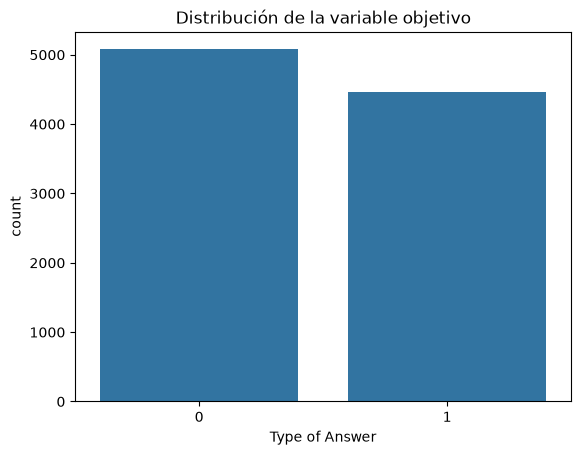

In [6]:
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))
sns.countplot(x=TARGET, data=df)
plt.title('Distribución de la variable objetivo')
plt.show()

## 3. Variables categóricas

In [7]:
for col in ['Student Country', 'Question Level', 'Topic', 'Subtopic']:
    print(f'--- {col} ---')
    print(df[col].value_counts().head(15), '\n')

--- Student Country ---
Student Country
Portugal              5495
Lithuania             1443
Italy                 1358
Slovenia               755
Ireland                300
Russian Federation     107
Romania                 60
Spain                   28
Name: count, dtype: int64 

--- Question Level ---
Question Level
Basic       7844
Advanced    1702
Name: count, dtype: int64 

--- Topic ---
Topic
Linear Algebra                         5726
Fundamental Mathematics                 818
Complex Numbers                         592
Differentiation                         579
Analytic Geometry                       358
Statistics                              340
Numerical Methods                       310
Optimization                            182
Real Functions of a single variable     164
Integration                             144
Probability                             128
Differential Equations                  108
Graph Theory                             55
Set Theory              

In [8]:
# Tasa de respuestas correctas por categoría
for col in ['Student Country', 'Question Level', 'Topic', 'Subtopic']:
    tasa = df.groupby(col)[TARGET].agg(['mean', 'count']).sort_values('count', ascending=False)
    display(tasa.head(15))

,mean,count
Student Country,,
Portugal,0.453867,5495
Lithuania,0.435897,1443
Italy,0.446244,1358
Slovenia,0.687417,755
Ireland,0.460000,300
Russian Federation,0.345794,107
Romania,0.583333,60
Spain,0.428571,28


,mean,count
Question Level,,
Basic,0.461117,7844
Advanced,0.501175,1702


,mean,count
Topic,,
Linear Algebra,0.490220,5726
Fundamental Mathematics,0.465770,818
Complex Numbers,0.454392,592
Differentiation,0.341969,579
Analytic Geometry,0.488827,358
Statistics,0.479412,340
Numerical Methods,0.387097,310
Optimization,0.384615,182
Real Functions of a single variable,0.353659,164


,mean,count
Subtopic,,
Vector Spaces,0.463805,2749
Linear Transformations,0.503526,2127
Complex Numbers,0.454392,592
"Algebraic expressions, Equations, and Inequalities",0.387097,496
Linear Systems,0.561905,420
Analytic Geometry,0.488827,358
Statistics,0.479412,340
Elementary Geometry,0.586957,322
Derivatives,0.356467,317


## 4. Keywords

Cada celda tiene varias palabras clave separadas por coma.

In [9]:
keywords = df['Keywords'].str.split(',').explode().str.strip()
print('Keywords distintas:', keywords.nunique())
keywords.value_counts().head(20)

Keywords distintas: 193


Keywords
Span                                      1844
Subspace                                  1465
Linear combination                        1254
Basis                                     1112
Linear application                         824
Linearity                                  733
Range                                      713
Kernel                                     713
Dimension                                  615
Isomorphism                                587
Injective linear application               551
Matrix of a linear transformation          531
Simplify expressions                       496
Operations with complex numbers            461
Linear independence                        430
Linear dependence                          430
Inconsistent system                        420
Solution of linear system                  420
Undetermined solution of linear system     420
Consistent system                          420
Name: count, dtype: int64

## 5. Identificadores (`Student ID`, `Question ID`)

¿Cuántas respuestas hay por estudiante y por pregunta?

In [10]:
print(df['Student ID'].value_counts().describe())
print(df['Question ID'].value_counts().describe())

count    372.00000
mean      25.66129
std       48.48195
min        1.00000
25%        7.00000
50%       14.00000
75%       29.00000
max      727.00000
Name: count, dtype: float64
count    833.000000
mean      11.459784
std       18.431686
min        1.000000
25%        2.000000
50%        5.000000
75%       11.000000
max      103.000000
Name: count, dtype: float64


**Conclusión:** `Student ID` y `Question ID` son identificadores nominales con cardinalidad alta (372 y 833 valores). Su valor numérico no significa nada (el estudiante 647 no es "mayor" que el 41), así que **se descartan** como features. La información de cada pregunta ya está en `Question Level`, `Topic`, `Subtopic` y `Keywords`.

## 6. Duplicados y consistencia

Hay filas idénticas. Revisamos si son errores o reintentos de un mismo estudiante sobre la misma pregunta.

In [11]:
print('Filas duplicadas:', df.duplicated().sum())

pares = df.groupby(['Student ID', 'Question ID'])[TARGET].agg(['count', 'nunique'])
print('Pares estudiante-pregunta:', len(pares))
print('Pares con más de un intento:', (pares['count'] > 1).sum())
print('Pares cuyo resultado cambió entre intentos:', (pares['nunique'] > 1).sum())

Filas duplicadas: 2083
Pares estudiante-pregunta: 6782
Pares con más de un intento: 1457
Pares cuyo resultado cambió entre intentos: 681


In [12]:
# Jerarquía Topic -> Subtopic y consistencia de Question Level
print('Topics por subtopic (máx):', df.groupby('Subtopic')['Topic'].nunique().max())
print('Preguntas con más de un nivel:', (df.groupby('Question ID')['Question Level'].nunique() > 1).sum())

Topics por subtopic (máx): 1
Preguntas con más de un nivel: 1


**Conclusiones:**
- Los duplicados **no son errores de carga**: son reintentos (en varios casos el resultado cambia entre intentos). **Se mantienen**, porque son respuestas reales del dataset original.
- Cada subtopic pertenece a un único topic (hay jerarquía). Igual **se usan ambas** variables.
- Solo una pregunta tiene dos niveles distintos. Es una inconsistencia menor del dataset y se deja como está.

## 7. Transformación de categóricas a numéricas (Tarea 1.a)

| Variable | Encoding | Justificación |
|---|---|---|
| `Student ID`, `Question ID` | Se descartan | Identificadores sin significado numérico |
| `Question Level` | Binaria (Basic = 0, Advanced = 1) | Solo 2 valores |
| `Student Country` | One-hot | Nominal, sin orden |
| `Topic` | One-hot | Nominal, sin orden |
| `Subtopic` | One-hot | Nominal, sin orden |
| `Keywords` | Multi-hot (una columna 0/1 por keyword) | Cada respuesta tiene varias keywords |

In [13]:
df_proc = df.drop(columns=['Student ID', 'Question ID'])

# Binaria
df_proc['Question Level'] = (df_proc['Question Level'] == 'Advanced').astype(int)

# One-hot
df_proc = pd.get_dummies(df_proc, columns=['Student Country', 'Topic', 'Subtopic'],
                         prefix=['Country', 'Topic', 'Subtopic'], dtype=int)

# Multi-hot de keywords (se limpian los espacios alrededor de cada keyword)
kw = (df_proc.pop('Keywords').str.split(',')
      .apply(lambda l: ','.join(k.strip() for k in l))
      .str.get_dummies(sep=',')
      .add_prefix('KW_'))
df_proc = pd.concat([df_proc, kw], axis=1)

print(df_proc.shape)
df_proc.head()

(9546, 241)


,Type of Answer,Question Level,Country_Ireland,Country_Italy,Country_Lithuania,Country_Portugal,Country_Romania,Country_Russian Federation,Country_Slovenia,Country_Spain,...,KW_Unconstrained optimization,KW_Undetermined solution of linear system,KW_Union of sets,KW_Variance,KW_Venn diagram,KW_Volume of revolution,KW_and total probability rules,KW_multiplication,KW_x-simple region (type II),KW_y-simple region (type I)
0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
# Verificaciones
assert len(df_proc) == len(df)
assert df_proc.select_dtypes(exclude='number').empty, 'Quedaron columnas no numéricas'
assert kw.shape[1] == keywords.nunique()
print('Columnas: 1 target + 1 level +', df['Student Country'].nunique(), 'países +',
      df['Topic'].nunique(), 'topics +', df['Subtopic'].nunique(), 'subtopics +', kw.shape[1], 'keywords')

Columnas: 1 target + 1 level + 8 países + 14 topics + 24 subtopics + 193 keywords


In [15]:
df_proc.to_csv(DATOS_PROCESADOS / 'datos_procesados.csv', index=False)